# Graph Cuts: segmentar una imagen cortando un grafo

**Artículo central:** Boykov, Y. y Jolly, M.-P. (2001). *Interactive Graph Cuts for Optimal Boundary & Region Segmentation of Objects in N-D Images.* ICCV.


In [ ]:
import collections
import itertools
import subprocess
import sys

if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "PyMaxflow==1.3.2"], check=True)

import cv2
import maxflow
import matplotlib.pyplot as plt
import numpy as np

AZUL, NARANJA, ROJO, GRIS = "#2a78d6", "#eb6834", "#d62f2f", "#8a897f"
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})

def crear_escena(ruido=0.15, contraste=0.26, semilla=7):
    rng = np.random.default_rng(semilla)
    yy, xx = np.mgrid[:120, :160]
    gt = ((xx - 68) / 38) ** 2 + ((yy - 60) / 30) ** 2 <= 1
    # estructura delgada: servirá para ver el sesgo de encogimiento
    gt[58:61, 100:148] = True          
    img = 0.36 + contraste * gt + rng.normal(0, ruido, gt.shape)
    return np.clip(img, 0, 1).astype(np.float32), gt

def crear_semillas(forma=(120, 160)):
    objeto, fondo = np.zeros(forma, bool), np.zeros(forma, bool)
    objeto[52:68, 50:88] = True
    fondo[:8, :] = fondo[-8:, :] = True
    fondo[:, :8] = fondo[:, -8:] = True
    return objeto, fondo

def iou(pred, gt):
    return (pred & gt).sum() / max((pred | gt).sum(), 1)

def ver(ax, img, titulo, **kw):
    ax.imshow(img, **{"cmap": "gray", **kw}); ax.set_title(titulo, fontsize=11); ax.axis("off")

img, gt = crear_escena()
semilla_obj, semilla_fondo = crear_semillas()
print("Escena sintética:", img.shape, "| píxeles de objeto:", int(gt.sum()))

Escena sintética: (120, 160) | píxeles de objeto: 3694


## 1. La imagen como grafo

- Cada **píxel** es un nodo.
- Hay dos nodos especiales: **S** (objeto) y **T** (fondo).
- **t-links** unen cada píxel con S y T: dicen *a qué clase se parece*.
- **n-links** unen píxeles vecinos: dicen *qué tan caro es separarlos*.

Un **corte** separa S de T. Cada píxel queda del lado de S o de T: **cortar = segmentar**.

$$E(L)=\underbrace{\sum_p D_p(L_p)}_{\text{¿se parece a su clase?}}+\lambda\underbrace{\sum_{(p,q)\in\mathcal N} w_{pq}\,[L_p\ne L_q]}_{\text{¿el borde está en un lugar creíble?}}$$

$$D_p(c)=-\log P(I_p\mid c) \qquad\qquad w_{pq}=e^{-\beta (I_p-I_q)^2}$$

Separar dos píxeles **parecidos** cuesta mucho. Separar dos píxeles **distintos** cuesta poco, así que el corte tiende a seguir los bordes.

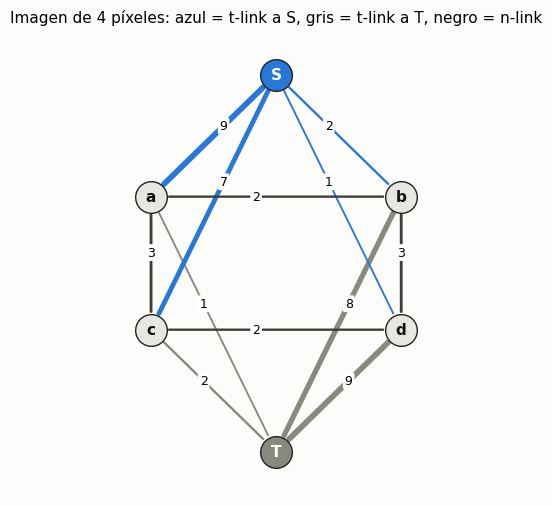

In [2]:
POS = {"S": (1.5, 3.25), "a": (.75, 2.15), "b": (2.25, 2.15), "c": (.75, .95), "d": (2.25, .95), "T": (1.5, -.15)}
T_LINKS = {"a": (9, 1), "b": (2, 8), "c": (7, 2), "d": (1, 9)}     # (capacidad desde S, capacidad hacia T)
N_LINKS = {("a", "b"): 2, ("a", "c"): 3, ("b", "d"): 3, ("c", "d"): 2}

def dibujar_grafo(ax, lado_s=None, titulo="", resaltar=()):
    def linea(u, v, peso, color):
        cortada = lado_s is not None and ((u in lado_s) != (v in lado_s))
        en_camino = (u, v) in resaltar or (v, u) in resaltar
        c = ROJO if cortada else NARANJA if en_camino else color
        (x0, y0), (x1, y1) = POS[u], POS[v]
        ax.annotate("", xy=(x1, y1), xytext=(x0, y0), zorder=1,
                    arrowprops=dict(arrowstyle="-", color=c, lw=1 + .35 * peso, ls="--" if cortada else "-",
                                    connectionstyle="arc3,rad=0", shrinkA=13, shrinkB=13))
        mx, my = x0 + (x1 - x0) * .42, y0 + (y1 - y0) * .42
        ax.text(mx, my, str(peso), ha="center", va="center", fontsize=9, zorder=3,
                bbox=dict(boxstyle="round,pad=.15", fc="white", ec="none"))
    for p, (cs, ct) in T_LINKS.items():
        linea("S", p, cs, AZUL); linea(p, "T", ct, GRIS)
    for (u, v), peso in N_LINKS.items():
        linea(u, v, peso, "#3f3e39")
    for n, (x, y) in POS.items():
        if n in "ST": fc = AZUL if n == "S" else GRIS
        elif lado_s is None: fc = "#e7e6e0"
        else: fc = "#a9cdf3" if n in lado_s else "#d5d4cd"
        ax.scatter(x, y, s=520, c=fc, edgecolors="#222", zorder=2)
        ax.text(x, y, n, ha="center", va="center", color="white" if n in "ST" else "#111", weight="bold", zorder=4)
    ax.set_xlim(.1, 2.9); ax.set_ylim(-.55, 3.65); ax.axis("off"); ax.set_title(titulo, fontsize=11)

fig, ax = plt.subplots(figsize=(5, 5.2))
dibujar_grafo(ax, titulo="Imagen de 4 píxeles: azul = t-link a S, gris = t-link a T, negro = n-link")
plt.tight_layout(); plt.show()

## 2. ¿Cómo se encuentra el corte mínimo?

Con 4 píxeles hay $2^4$ cortes. En una imagen de 160×120 hay $2^{19200}$: **no se pueden probar todos**.

El **teorema max-flow/min-cut** (Ford y Fulkerson, 1956) resuelve el problema: **el flujo máximo de S a T vale exactamente lo mismo que el corte mínimo**.

Imagina tuberías: empujamos agua de S a T hasta que ya no cabe más. Las tuberías saturadas forman el corte.

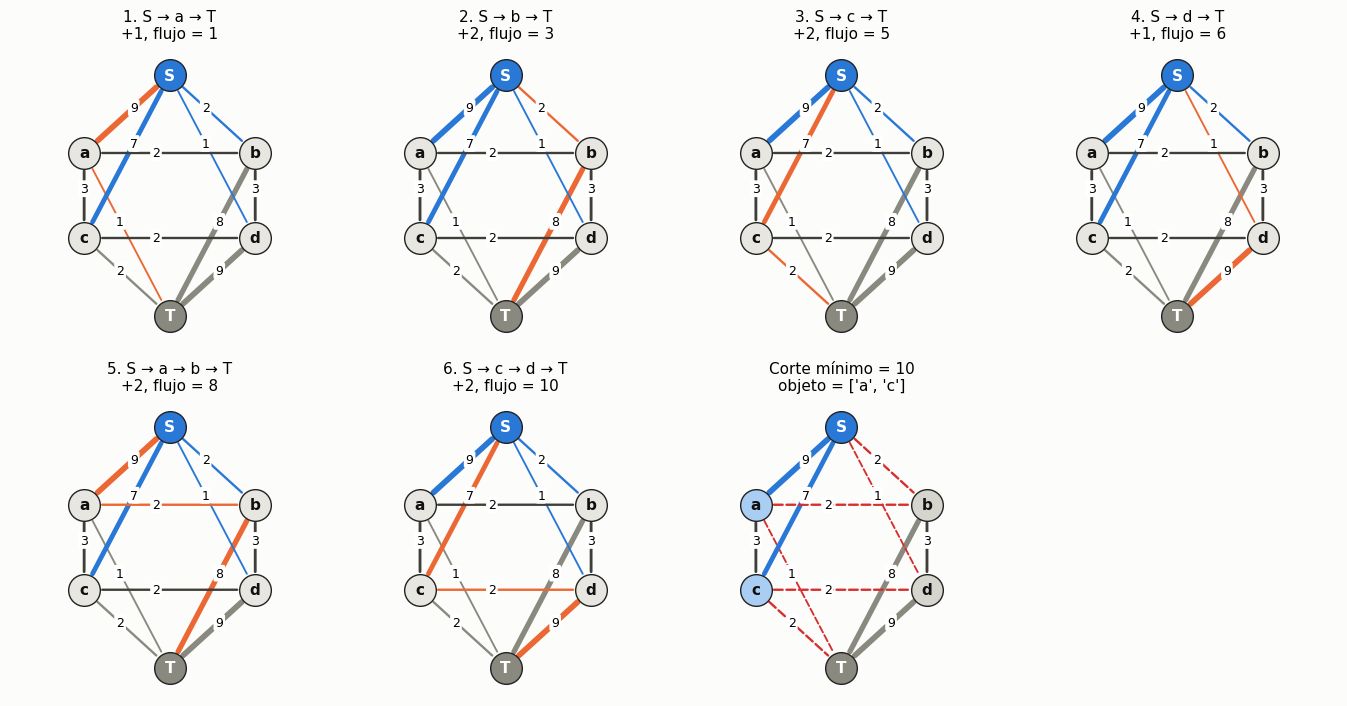

In [3]:
def capacidades():
    cap = collections.defaultdict(int)
    for p, (cs, ct) in T_LINKS.items():
        cap["S", p] = cs; cap[p, "T"] = ct
    for (u, v), peso in N_LINKS.items():
        cap[u, v] = peso; cap[v, u] = peso
    return cap

def edmonds_karp(cap):
    res, flujo, pasos = collections.defaultdict(int, cap), 0, []
    nodos = list(POS)
    while True:
        previo, cola = {"S": None}, collections.deque(["S"])
        while cola and "T" not in previo:
            u = cola.popleft()
            for v in nodos:
                if v not in previo and res[u, v] > 0:
                    previo[v] = u; cola.append(v)
        if "T" not in previo:
            return flujo, set(previo), pasos           # lo alcanzable desde S es el lado del objeto
        camino, v = [], "T"
        while previo[v] is not None:
            camino.append((previo[v], v)); v = previo[v]
        camino.reverse()
        delta = min(res[e] for e in camino)
        for u, v in camino:
            res[u, v] -= delta; res[v, u] += delta
        flujo += delta
        pasos.append((camino, delta, flujo))

flujo, lado_s, pasos = edmonds_karp(capacidades())

n = len(pasos) + 1
fig, axes = plt.subplots(2, (n + 1) // 2, figsize=(3.4 * ((n + 1) // 2), 7.2))
axes = axes.ravel()
for i, (camino, delta, acumulado) in enumerate(pasos):
    ruta = " → ".join(["S"] + [v for _, v in camino])
    dibujar_grafo(axes[i], resaltar=camino, titulo=f"{i + 1}. {ruta}\n+{delta}, flujo = {acumulado}")
dibujar_grafo(axes[n - 1], lado_s=lado_s, titulo=f"Corte mínimo = {flujo}\nobjeto = {sorted(lado_s - {'S'})}")
for a in axes[n:]: a.axis("off")
plt.tight_layout(); plt.show()

**Comprobación:** probamos las 16 segmentaciones posibles por fuerza bruta y las comparamos con el flujo máximo y con PyMaxflow, la biblioteca de Boykov y Kolmogorov.

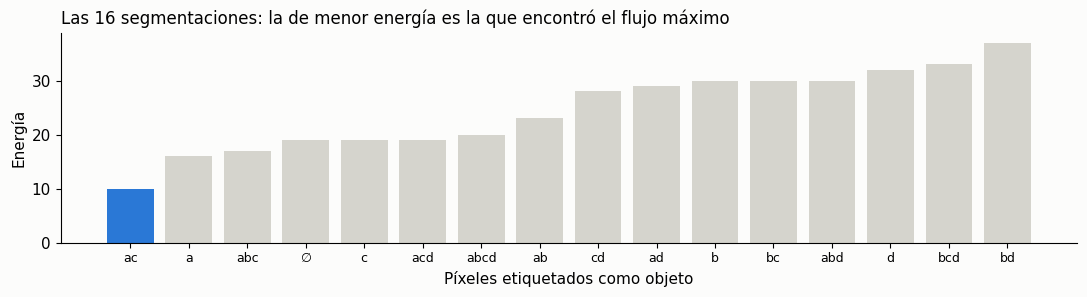

Fuerza bruta: 10 | Edmonds-Karp: 10 | PyMaxflow: 10


In [4]:
def energia(objeto):
    costo = sum(ct if p in objeto else cs for p, (cs, ct) in T_LINKS.items())
    return costo + sum(w for (u, v), w in N_LINKS.items() if (u in objeto) != (v in objeto))

todas = [set(c) for r in range(5) for c in itertools.combinations("abcd", r)]
todas.sort(key=energia)
valores = [energia(s) for s in todas]

g = maxflow.Graph[int]()
ids = {p: g.add_nodes(1)[0] for p in "abcd"}
for p, (cs, ct) in T_LINKS.items(): g.add_tedge(ids[p], cs, ct)
for (u, v), w in N_LINKS.items(): g.add_edge(ids[u], ids[v], w, w)
flujo_lib = g.maxflow()
objeto_lib = {p for p in "abcd" if g.get_segment(ids[p]) == 0}

fig, ax = plt.subplots(figsize=(11, 3.1))
ax.bar(range(16), valores, color=[AZUL if v == min(valores) else "#d5d4cd" for v in valores])
ax.set_xticks(range(16), ["".join(sorted(s)) or "∅" for s in todas], fontsize=9)
ax.set_ylabel("Energía"); ax.set_xlabel("Píxeles etiquetados como objeto")
ax.set_title("Las 16 segmentaciones: la de menor energía es la que encontró el flujo máximo", loc="left", fontsize=12)
plt.tight_layout(); plt.show()

print(f"Fuerza bruta: {min(valores)} | Edmonds-Karp: {flujo} | PyMaxflow: {flujo_lib}")
assert min(valores) == flujo == flujo_lib and objeto_lib == lado_s - {"S"} == todas[0]

## 3. El algoritmo completo, paso a paso

1. El usuario marca **semillas** de objeto y de fondo.
2. Con ellas se aprende un **histograma** para cada clase.
3. Se calculan los **t-links** con $-\log P$.
4. Se calculan los **n-links** con el contraste entre vecinos.
5. Las semillas se vuelven **restricciones duras**, con capacidad $K$ muy grande.
6. **Max-flow** entrega la segmentación óptima global de esta energía.

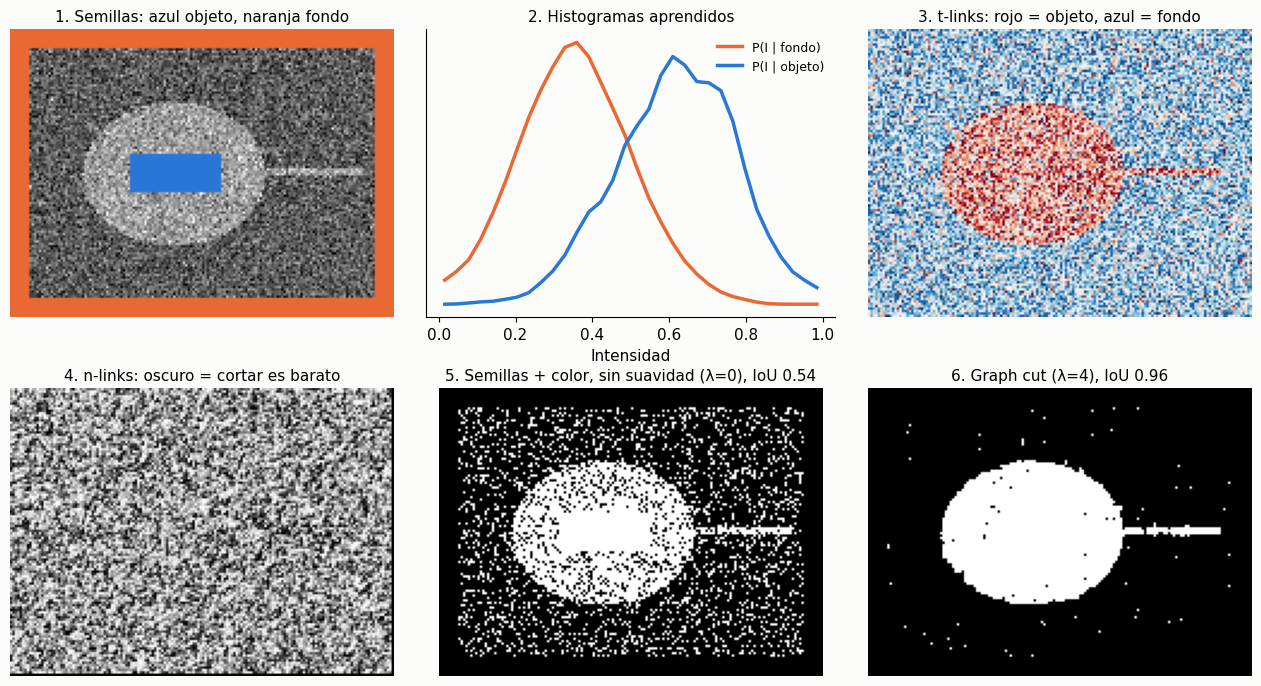

In [5]:
def modelo_color(img, semilla, bins=32):
    h, _ = np.histogram(img[semilla], bins=bins, range=(0, 1))
    k = cv2.getGaussianKernel(7, 1).ravel()
    h = np.convolve(h.astype(float), k, mode="same") + 1e-3
    return h / h.sum()

def costos(img, s_obj, s_fondo, bins=32):
    q = np.minimum((img * bins).astype(int), bins - 1)
    p_obj, p_fondo = modelo_color(img, s_obj, bins), modelo_color(img, s_fondo, bins)
    return -np.log(p_obj[q]), -np.log(p_fondo[q]), p_obj, p_fondo

def pesos(img):
    dh, dv = (img[:, 1:] - img[:, :-1]) ** 2, (img[1:] - img[:-1]) ** 2
    beta = 1 / (2 * np.concatenate((dh.ravel(), dv.ravel())).mean() + 1e-9)
    return np.pad(np.exp(-beta * dh), ((0, 0), (0, 1))), np.pad(np.exp(-beta * dv), ((0, 1), (0, 0)))

def graph_cut(img, s_obj, s_fondo, lam):
    D_obj, D_fondo, _, _ = costos(img, s_obj, s_fondo)
    w_h, w_v = pesos(img)
    g = maxflow.Graph[float]()
    nodos = g.add_grid_nodes(img.shape)
    g.add_grid_edges(nodos, lam * w_h, structure=np.array([[0, 0, 0], [0, 0, 1], [0, 0, 0]]), symmetric=True)
    g.add_grid_edges(nodos, lam * w_v, structure=np.array([[0, 0, 0], [0, 0, 0], [0, 1, 0]]), symmetric=True)
    desde_s, hacia_t = D_fondo.copy(), D_obj.copy()          # S = objeto: quien queda en S paga hacia T
    K = 1e6
    desde_s[s_obj], hacia_t[s_obj] = K, 0
    desde_s[s_fondo], hacia_t[s_fondo] = 0, K
    g.add_grid_tedges(nodos, desde_s, hacia_t)
    g.maxflow()
    return ~g.get_grid_segments(nodos)

D_obj, D_fondo, p_obj, p_fondo = costos(img, semilla_obj, semilla_fondo)
w_h, w_v = pesos(img)

vista = np.dstack([img] * 3).copy()
vista[semilla_obj] = (.16, .47, .84); vista[semilla_fondo] = (.92, .41, .2)
x = (np.arange(32) + .5) / 32

fig, ax = plt.subplots(2, 3, figsize=(13, 7))
ver(ax[0, 0], vista, "1. Semillas: azul objeto, naranja fondo")
ax[0, 1].plot(x, p_fondo, color=NARANJA, lw=2.5, label="P(I | fondo)")
ax[0, 1].plot(x, p_obj, color=AZUL, lw=2.5, label="P(I | objeto)")
ax[0, 1].set_title("2. Histogramas aprendidos", fontsize=11); ax[0, 1].set_xlabel("Intensidad"); ax[0, 1].set_yticks([]); ax[0, 1].legend(frameon=False, loc="upper right", fontsize=9)
ver(ax[0, 2], D_fondo - D_obj, "3. t-links: rojo = objeto, azul = fondo", cmap="RdBu_r", vmin=-4, vmax=4)
ver(ax[1, 0], np.minimum(w_h, w_v), "4. n-links: oscuro = cortar es barato", vmin=0, vmax=1)
r0 = graph_cut(img, semilla_obj, semilla_fondo, 0)
ver(ax[1, 1], r0, f"5. Semillas + color, sin suavidad (λ=0), IoU {iou(r0, gt):.2f}")
r = graph_cut(img, semilla_obj, semilla_fondo, 4)
ver(ax[1, 2], r, f"6. Graph cut (λ=4), IoU {iou(r, gt):.2f}")
plt.tight_layout(); plt.show()

### Prueba tú: el efecto de λ

λ controla cuánto importa la suavidad frente al color. En Colab, mueve el control y vuelve a ejecutar la celda.

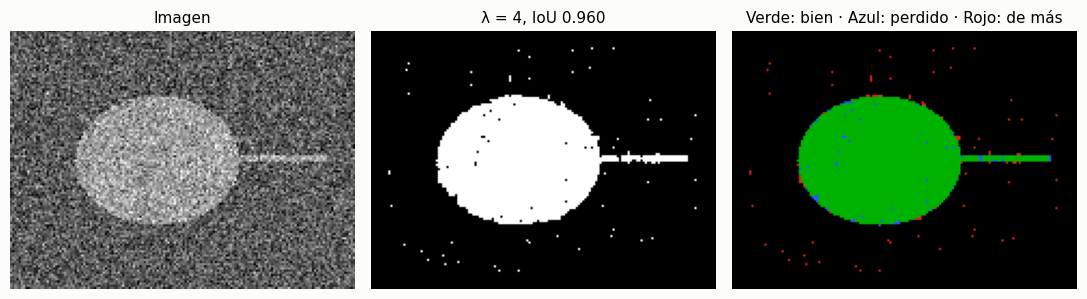

In [6]:
lam = 4 #@param {type:"slider", min:0, max:12, step:0.25}

r = graph_cut(img, semilla_obj, semilla_fondo, lam)
fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))
ver(ax[0], img, "Imagen", vmin=0, vmax=1)
ver(ax[1], r, f"λ = {lam}, IoU {iou(r, gt):.3f}")
error = np.zeros((*gt.shape, 3)); error[r & gt] = (0, .7, 0); error[~r & gt] = (.16, .35, 1); error[r & ~gt] = (.9, .12, .12)
ver(ax[2], error, "Verde: bien · Azul: perdido · Rojo: de más")
plt.tight_layout(); plt.show()

## 4. Ventajas y desventajas

| ✅ Ventajas | ⚠️ Desventajas |
|---|---|
| **Óptimo global** para energías binarias submodulares | Óptimo **de la energía**, no necesariamente de la tarea |
| Combina región, borde y semillas | Depende de elegir bien **λ** |
| Funciona en **N dimensiones** (2D, 3D, video) | Tiende a **recortar estructuras delgadas** |
| Corregir es fácil: se agregan semillas | Sufre si **objeto y fondo comparten color** |
| No requiere datos de entrenamiento | Grafo grande en imágenes 3D: memoria y tiempo |

Las siguientes celdas **provocan** dos de estas fallas.

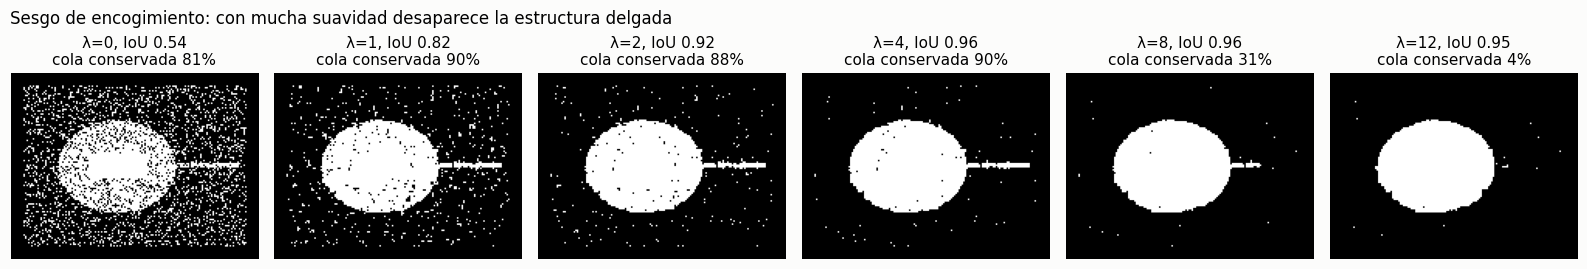

In [7]:
valores_lam = [0, 1, 2, 4, 8, 12]
resultados = {l: graph_cut(img, semilla_obj, semilla_fondo, l) for l in valores_lam}
region_cola = np.zeros_like(gt); region_cola[58:61, 112:148] = True

fig, ax = plt.subplots(1, 6, figsize=(16, 2.9))
for a, l in zip(ax, valores_lam):
    cola = resultados[l][region_cola].mean()
    ver(a, resultados[l], f"λ={l}, IoU {iou(resultados[l], gt):.2f}\ncola conservada {cola:.0%}")
fig.suptitle("Sesgo de encogimiento: con mucha suavidad desaparece la estructura delgada", x=.01, ha="left", fontsize=12)
plt.tight_layout(); plt.show()

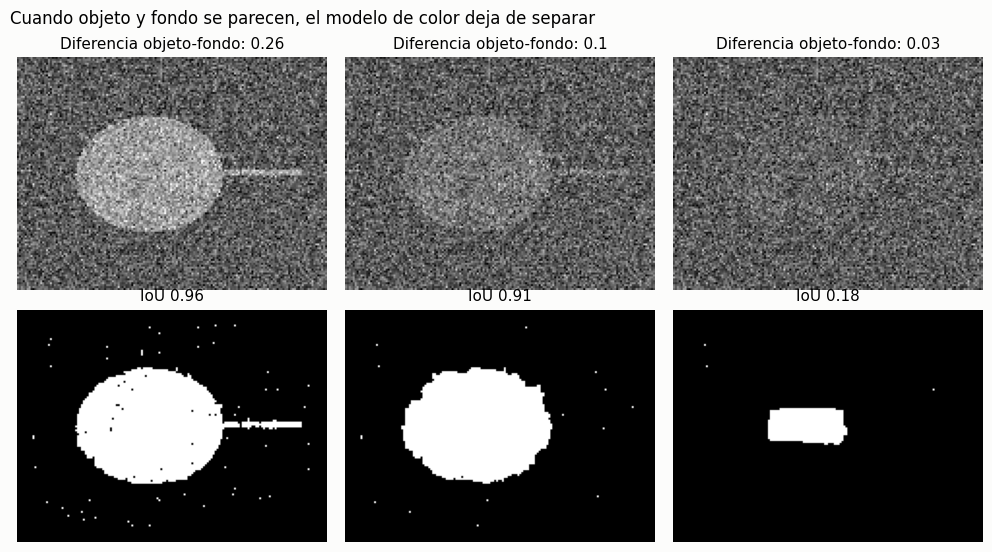

In [8]:
contrastes = [.26, .10, .03]
fig, ax = plt.subplots(2, 3, figsize=(10, 5.6))
for j, c in enumerate(contrastes):
    im, _ = crear_escena(contraste=c)
    r = graph_cut(im, semilla_obj, semilla_fondo, 4)
    ver(ax[0, j], im, f"Diferencia objeto-fondo: {c}", vmin=0, vmax=1)
    ver(ax[1, j], r, f"IoU {iou(r, gt):.2f}")
fig.suptitle("Cuando objeto y fondo se parecen, el modelo de color deja de separar", x=.01, ha="left", fontsize=12)
plt.tight_layout(h_pad=1.6); plt.show()

## 5. ¿Cuándo usarlo y dónde se aplica?

**Conviene** cuando hay pocas imágenes o no hay datos etiquetados, se pueden obtener semillas y las regiones tienen apariencia distinta.

**No conviene** cuando la clase depende de semántica ("esto es un perro") o de un contexto que el color y el contraste no capturan. Ahí suele ganar el aprendizaje profundo.

| Área | Ejemplo |
|---|---|
| 🏥 **Imagen médica** | Órganos en CT y MRI, el caso N-D del artículo original |
| 🖼️ **Edición de fotos** | Quitar fondos con GrabCut (Rother et al., 2004) |
| 👓 **Visión estéreo** | Mapas de disparidad con α-expansión (Boykov et al., 2001) |
| 🎬 **Video** | Segmentación espacio-temporal, tratando el tiempo como otra dimensión |
| 🤖 **Robótica** | **Nuestro demo:** detectar suelo transitable en un TurtleBot 4 simulado |

## 6. Conclusión

1. Graph Cuts convierte segmentar en **cortar un grafo**.
2. El teorema max-flow/min-cut permite hallar el **óptimo global** en tiempo práctico.
3. Su calidad depende de lo que codifica la energía: **semillas, color y λ**.

➡️ **En el notebook de demo** (`demo.ipynb`) aplicamos esto a imágenes reales de simulación, sin semillas manuales.

## Referencias

1. Boykov, Y. y Jolly, M.-P. (2001). Interactive graph cuts for optimal boundary & region segmentation of objects in N-D images. *ICCV*, 105–112.
2. Ford, L. R. y Fulkerson, D. R. (1956). Maximal flow through a network. *Canadian Journal of Mathematics*, 8, 399–404.
3. Greig, D., Porteous, B. y Seheult, A. (1989). Exact maximum a posteriori estimation for binary images. *Journal of the Royal Statistical Society B*, 51(2), 271–279.
4. Boykov, Y., Veksler, O. y Zabih, R. (2001). Fast approximate energy minimization via graph cuts. *IEEE TPAMI*, 23(11), 1222–1239.
5. Boykov, Y. y Kolmogorov, V. (2004). An experimental comparison of min-cut/max-flow algorithms for energy minimization in vision. *IEEE TPAMI*, 26(9), 1124–1137.
6. Kolmogorov, V. y Zabih, R. (2004). What energy functions can be minimized via graph cuts? *IEEE TPAMI*, 26(2), 147–159.
7. Rother, C., Kolmogorov, V. y Blake, A. (2004). "GrabCut": Interactive foreground extraction using iterated graph cuts. *ACM Transactions on Graphics*, 23(3), 309–314.